# Digit Diffusion

An unconditional diffusion model generates eight-by-eight handwritten digits. The denoiser is a small multilayer perceptron with timestep features.

In [1]:
from pathlib import Path
import sys

start = Path.cwd()
for parent in (start, *start.parents):
    if (parent / "gallery" / "__init__.py").is_file():
        sys.path.insert(0, str(parent))
        break
else:
    raise RuntimeError("Open this example inside the Machine Learning collection.")

## Model and reference data

The digits span ten classes. Only images from the training split enter the diffusion objective.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from gallery.neural import seed_cpu
from gallery.diffusion import (
    NoisePredictor,
    NoiseSchedule,
    train_noise,
    heldout_noise,
    sample,
    distribution_scores,
    training_bandwidth,
)

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from scipy.spatial.distance import jensenshannon
from gallery.vision import digits_split

## Predict pixel noise

Images are mapped to the interval from minus one to one. A fixed independent noise draw measures held-out denoising loss.

In [3]:
seed_cpu()
train, test, y, y_test = digits_split()
X = torch.tensor(2 * train.reshape(len(train), -1) - 1)
T = torch.tensor(2 * test.reshape(len(test), -1) - 1)
schedule = NoiseSchedule(48)
net = NoisePredictor(64, 192)
history = train_noise(net, schedule, X, updates=2400)
heldout_noise(net, schedule, T)

Held-out epsilon MSE 0.267 | zero-predictor MSE 1.003


## Inspect generated digits

A classifier fitted on real training images estimates label coverage. Its accuracy is reported on real held-out digits so the diagnostic can be interpreted.

Digit probe accuracy on real test images: 0.973
Generated class counts: [43, 11, 24, 54, 11, 64, 15, 23, 26, 49]
Class-histogram Jensen–Shannon distance: 0.242
Training reference: pixel MMD² 0.0014 | sliced Wasserstein 0.048
Generated: pixel MMD² 0.0437 | sliced Wasserstein 0.194


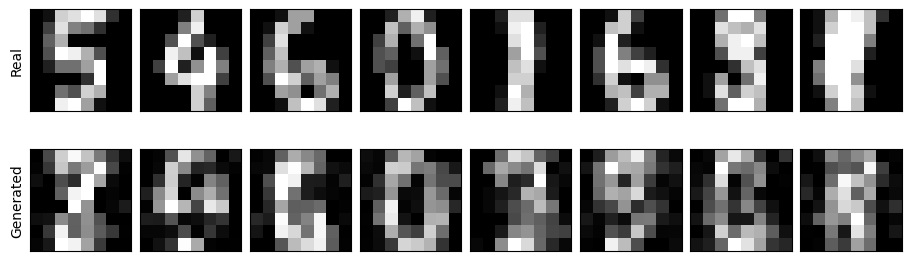

In [4]:
initial = torch.randn((320, 64), generator=torch.Generator().manual_seed(97))
generated = sample(net, schedule, initial, "ddpm", limit=1.0)
probe = LogisticRegression(C=1, max_iter=1500).fit(X.numpy(), y)
predicted = probe.predict(generated)
print(
    f"Digit probe accuracy on real test images: {accuracy_score(y_test,probe.predict(T.numpy())):.3f}"
)
counts = np.bincount(predicted, minlength=10)
reference_counts = np.bincount(y_test, minlength=10)
print("Generated class counts:", counts.tolist())
print(
    f"Class-histogram Jensen–Shannon distance: {jensenshannon(counts,reference_counts,base=2):.3f}"
)
width = training_bandwidth(X.numpy())
for label, samples in [("Training reference", X[:320].numpy()), ("Generated", generated)]:
    mmd, sw = distribution_scores(T[:320].numpy(), samples, width)
    print(f"{label}: pixel MMD² {mmd:.4f} | sliced Wasserstein {sw:.3f}")
fig, axes = plt.subplots(2, 8, figsize=(9, 2.8), constrained_layout=True)
for j in range(8):
    for row, images in enumerate([T.numpy(), generated]):
        ax = axes[row, j]
        ax.imshow(images[j].reshape(8, 8), cmap="gray", vmin=-1, vmax=1)
        ax.set_xticks([])
        ax.set_yticks([])
axes[0, 0].set_ylabel("Real")
axes[1, 0].set_ylabel("Generated")
plt.show()

## Reading the result

The displayed images are the first eight generated samples. A classifier can assign a label to an implausible image, so label coverage should be read alongside the samples and distribution distances.

## References

[Ho, Jain and Abbeel, Denoising Diffusion Probabilistic Models (2020)](https://arxiv.org/abs/2006.11239)

[Nichol and Dhariwal, Improved Denoising Diffusion Probabilistic Models (2021)](https://arxiv.org/abs/2102.09672)

[Alpaydin and Kaynak, Optical Recognition of Handwritten Digits, UCI, CC BY 4.0](https://doi.org/10.24432/C50P49)

[Noise schedule, training objective and reverse samplers](../../gallery/diffusion.py)